# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2: Mô hình hóa chất lượng rượu vang Red Wine Quality (Mục 4 trang 26)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
- Đọc tập dữ liệu Red Wine Quality.
- Tính toán ma trận hệ số tương quan Pearson giữa 11 chỉ số hóa lý.
- Trực quan hóa bằng biểu đồ Heatmap của Seaborn và nhận xét.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu Red Wine Quality: (1599, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None


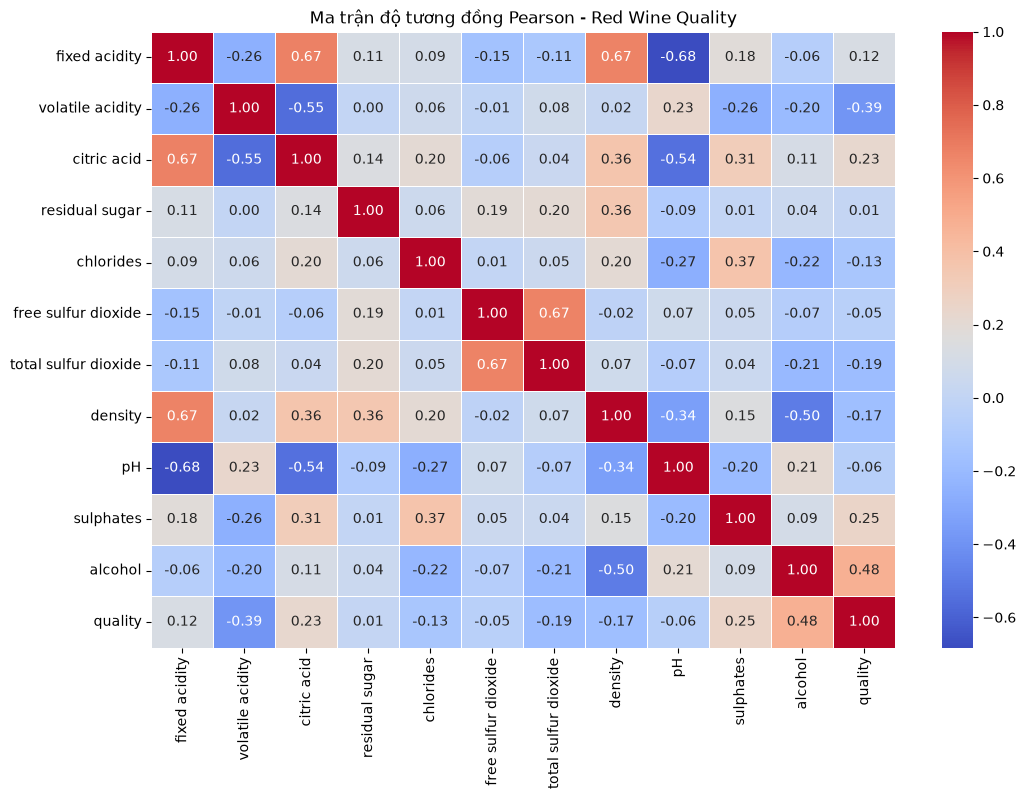


Nhận xét tương quan:
1. Cặp 'fixed acidity' và 'citric acid' có tương quan dương (r = 0.67), 'fixed acidity' và 'density' (r = 0.67) do tính chất hóa lý của nồng độ axit ảnh hưởng đến mật độ rượu.
2. Cặp 'free sulfur dioxide' và 'total sulfur dioxide' có tương quan dương (r = 0.67) do SO2 tự do là một phần của tổng SO2.
3. Cặp 'fixed acidity' và 'pH' có tương quan âm mạnh (r = -0.68) do pH tỷ lệ nghịch với nồng độ ion hydro của axit.
4. Không có cặp thuộc tính nào có hệ số tương quan vượt quá ngưỡng loại bỏ (|r| > 0.85). Do đó, toàn bộ 11 thuộc tính dự đoán được giữ nguyên.


In [2]:
# Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
wine_path = get_data_path("winequality-red.csv")
df_wine = pd.read_csv(wine_path)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập dữ liệu Red Wine Quality: {df_wine.shape}")
print(df_wine.info())

# Khảo sát ma trận tương quan Pearson giữa các thuộc tính đặc trưng
plt.figure(figsize=(12, 8))
corr_wine = df_wine.corr(method='pearson')
sns.heatmap(corr_wine, annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title("Ma trận độ tương đồng Pearson - Red Wine Quality")
plt.show()

print()
print("Nhận xét tương quan:")
print("1. Cặp 'fixed acidity' và 'citric acid' có tương quan dương (r = 0.67), 'fixed acidity' và 'density' (r = 0.67) do tính chất hóa lý của nồng độ axit ảnh hưởng đến mật độ rượu.")
print("2. Cặp 'free sulfur dioxide' và 'total sulfur dioxide' có tương quan dương (r = 0.67) do SO2 tự do là một phần của tổng SO2.")
print("3. Cặp 'fixed acidity' và 'pH' có tương quan âm mạnh (r = -0.68) do pH tỷ lệ nghịch với nồng độ ion hydro của axit.")
print("4. Không có cặp thuộc tính nào có hệ số tương quan vượt quá ngưỡng loại bỏ (|r| > 0.85). Do đó, toàn bộ 11 thuộc tính dự đoán được giữ nguyên.")

### Câu 4: Tách các cột dữ liệu thành hai phần
- Phần 1 (X): Chứa 11 thuộc tính hóa lý đo đạc được (features).
- Phần 2 (y): Chứa thuộc tính quyết định 'quality' (target).

In [3]:
# Câu 4: Tách các cột dữ liệu thành hai phần
X = df_wine.drop(columns=['quality'])
y = df_wine['quality']

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập thuộc tính dự đoán (X): {X.shape}")
print(f"Kích thước thuộc tính quyết định (y): {y.shape}")
print(f"Danh sách các thang điểm chất lượng rượu (classes): {sorted(y.unique().tolist())}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập thuộc tính dự đoán (X): (1599, 11)
Kích thước thuộc tính quyết định (y): (1599,)
Danh sách các thang điểm chất lượng rượu (classes): [3, 4, 5, 6, 7, 8]
